---
authors:
  - name: Lukas Heumos
  - name: Luis Heinzlmeier
  - name: Isaac Virshup
    roles:
      - writing – review & editing
---


# Spatial data structures


This chapter assumes familiarity with AnnData and scanpy from the [fundamental data structures chapter](../introduction/fundamental_data_structures_and_frameworks.ipynb).
It introduces SpatialData for spatially resolved data and Squidpy for analyzing it.

In [1]:
import os
import warnings

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"

(spatial-data-structures-key-takeaway-1)=
## Using SpatialData to store multimodal and spatial data

Spatial omics refers to technologies that measure molecular information (gene expression, chromatin accessibility, proteins) while preserving their physical location inside a tissue.
Traditional single-cell methods lose spatial context during tissue dissociation, whereas spatial omics retains both molecular profiles and spatial positions of individual cells.
Because these datasets combine images, coordinates, and multiple molecular measurements, they are large, complex, and require specialized spatially aware data structures.
SpatialData unifies raw and processed data from multiple spatial omics technologies {cite:p}`at:Marconato2025`.
Its five primitive elements (SpatialElements) are saved in a Zarr store following the OME–NGFF standard, a standardized format for bioimaging data.

### Installation and importing
SpatialData is available on PyPI and Conda.
```bash
pip install spatialdata
conda install -c conda-forge spatialdata
```



### Key terms and data model
We can think of a `SpatialData` object as a container for various `Elements`. An `Element` is either a `SpatialElement` (`Images`, `Labels`, `Points`, `Shapes`) or a `Table`. Here is a brief description:
- `Images`: H&E, staining images
- `Labels`: pixel-level segmentation
- `Points`: transcripts locations with gene information, landmarks points
- `Shapes`: cell/nucleus boundaries, subcellular structures, anatomical annotations, regions of interest (ROIs)
- `Tables`: sparse/dense matrices annotating the `SpatialElements` or storing arbitrary (non-spatial) metadata. They do not contain spatial coordinates.

We can categorize the `SpatialElements` into two broad types:
- `Rasters`: Data made up of pixels: including `Images` and `Labels`
- `Vectors`: Data made up of points and lines. Polygons are also vectors, since they are simply a list of connected points. `Points` and `Shapes` are elements of this type.

:::{figure} ../_static/images/advanced_data_structures_and_frameworks/SpacialData_elements.png
:name: spacialdata-fig
:alt: Overview of SpacialData

The elements of a SpatialData object. Obtained from .
:::


In [2]:
import lamindb as ln
import spatialdata as sd
import spatialdata_plot  # noqa: F401

ln.connect("theislab/sc-best-practices")

ln.track("V5rbUBUZEjHh")

→ connected lamindb: theislab/sc-best-practices
! It looks like you are running jupyter lab but don't have jupyter-server module installed. Please install it via pip install jupyter-server
→ loaded Transform('V5rbUBUZEjHh0000', key='data_structures.ipynb'), started new Run('XiKhNtBdq2vjriDz') at 2026-10-19 13:23:19 UTC


Let’s load a mouse liver dataset using `lamindb`. The original dataset is available [here](https://s3.embl.de/spatialdata/spatialdata-sandbox/mouse_liver.zip).

In [3]:
# Suppress ome-zarr's "no parent found" log message which indicates a minor structural inconsistency in the Zarr store that does not affect data loading.
import logging

logging.getLogger("ome_zarr").setLevel(logging.ERROR)

In [4]:
sdata = ln.Artifact.get(
    key="introduction/advanced_data_structures_and_frameworks_spatialdata.zarr"
).load()
sdata

SpatialData object, with associated Zarr store: /home/lheumos/.cache/lamindb/lamin-eu-central-1/VPwcjx3CDAa2/introduction/advanced_data_structures_and_frameworks_spatialdata.zarr
├── Images
│     └── 'raw_image': DataTree[cyx] (1, 6432, 6432), (1, 1608, 1608)
├── Labels
│     └── 'segmentation_mask': DataArray[yx] (6432, 6432)
├── Points
│     └── 'transcripts': DataFrame with shape: (1153548, 3) (2D points)
├── Shapes
│     └── 'nucleus_boundaries': GeoDataFrame shape: (3375, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (3375, 99)
with coordinate systems:
    ▸ 'global', with elements:
        raw_image (Images), segmentation_mask (Labels), transcripts (Points), nucleus_boundaries (Shapes)

In [5]:
# Reset ome-zarr logging level back to default
logging.getLogger("ome_zarr").setLevel(logging.WARNING)

### Explore the `Elements` of the `SpatialData` object

Let's explore each element type and how they are represented:
- Images: [`xarray.DataArray`](https://docs.xarray.dev/en/stable/generated/xarray.DataArray.html) or [`xarray.DataTree`](https://docs.xarray.dev/en/stable/generated/xarray.DataTree.html) objects respectively for single-scale or multi-scale images
- Labels: [`xarray.DataArray`](https://docs.xarray.dev/en/stable/generated/xarray.DataArray.html) or [`xarray.DataTree`](https://docs.xarray.dev/en/stable/generated/xarray.DataTree.html) objects containing integer codes for different labels
- Points: [`dask.DataFrame`](https://docs.dask.org/en/stable/dataframe.html) objects containing point coordinates, (lazy version of [`pandas.DataFrame`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html) objects)
- Shapes: [`geopandas.GeoDataFrame`](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.html) objects containing geometric objects like polygons
- Tables: [`anndata.AnnData`](https://anndata.readthedocs.io/en/stable/generated/anndata.AnnData.html) objects for tabular data with annotations


(code-cell)=

In [6]:
sdata["raw_image"]

<xarray.DataTree>
Group: /
├── Group: /scale0
│       Dimensions:  (c: 1, y: 6432, x: 6432)
│       Coordinates:
│         * c        (c) int64 8B 0
│         * y        (y) float64 51kB 0.5 1.5 2.5 3.5 ... 6.43e+03 6.43e+03 6.432e+03
│         * x        (x) float64 51kB 0.5 1.5 2.5 3.5 ... 6.43e+03 6.43e+03 6.432e+03
│       Data variables:
│           image    (c, y, x) uint16 83MB dask.array<chunksize=(1, 256, 256), meta=np.ndarray>
└── Group: /scale1
        Dimensions:  (c: 1, y: 1608, x: 1608)
        Coordinates:
          * c        (c) int64 8B 0
          * y        (y) float64 13kB 2.0 6.0 10.0 14.0 ... 6.422e+03 6.426e+03 6.43e+03
          * x        (x) float64 13kB 2.0 6.0 10.0 14.0 ... 6.422e+03 6.426e+03 6.43e+03
        Data variables:
            image    (c, y, x) uint16 5MB dask.array<chunksize=(1, 256, 256), meta=np.ndarray>

Images can have multiple scales, which are stored in a pyramid for downsampled representations useful for more efficient visualization and analysis. 
We can access a single scale using the `get_pyramid_levels` function, where `0` is the highest resolution, `1` is downsampled by a factor of (usually 2), `2` is downsampled by another factor (usually 2, with respect to the previous scale), etc.

In this case, our image has 2 scales (check out groups of the output from the code cell [above](code-cell)). Let's access the highest resolution image.

In [7]:
sd.get_pyramid_levels(sdata["raw_image"], n=1)

<xarray.DataArray 'image' (c: 1, y: 1608, x: 1608)> Size: 5MB
dask.array<from-zarr, shape=(1, 1608, 1608), dtype=uint16, chunksize=(1, 256, 256), chunktype=numpy.ndarray>
Coordinates:
  * c        (c) int64 8B 0
  * y        (y) float64 13kB 2.0 6.0 10.0 14.0 ... 6.422e+03 6.426e+03 6.43e+03
  * x        (x) float64 13kB 2.0 6.0 10.0 14.0 ... 6.422e+03 6.426e+03 6.43e+03
Attributes:
    transform:  {'global': Sequence \n    Scale (y, x)\n        [4. 4.]\n    ...

To view image properties such as axes and channel names, `SpatialData` provides some helper functions.
More helper functions can be found in the [API](https://spatialdata.scverse.org/en/stable/api.html) page.
The axes `x` and `y` represent the two-dimensional plane of the image, while `c` corresponds to the different channels (e.g., wavelength) within the image.

In [8]:
sd.models.get_axes_names(sdata["raw_image"])

('c', 'y', 'x')

Here we see that our image only has one channel for DAPI staining (highlights nucleus).

In [9]:
sd.models.get_channel_names(sdata["raw_image"])

[0]

Let's use `spatialdata-plot` to show the image (DAPI staining for nuclei).

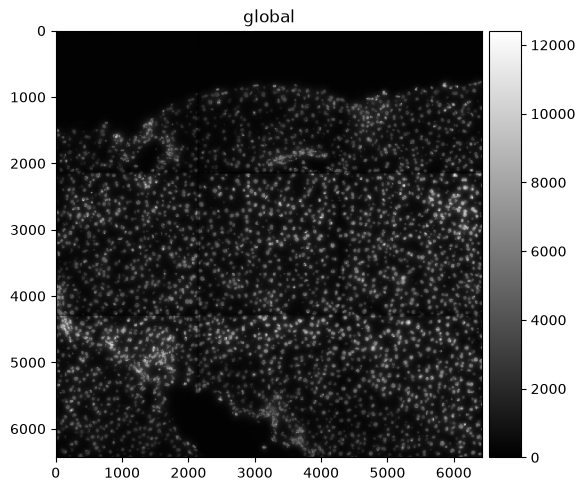

In [10]:
sdata.pl.render_images("raw_image", cmap="gray").pl.show()

### Points

Points are represented as `dask.DataFrame` objects containing point coordinates (lazy version of `pandas.DataFrame` objects).
Lazy-loading the `DataFrame` reduces memory usage, as the information is only retrieved from the data file when it is needed and not all at once.
For spatial transcriptomics datasets measuring single-molecules, coordinates are stored in columns `x` and `y` (optionally `z` for 3D) and have an additional column annotating gene identity.

In [11]:
sdata["transcripts"]

,x,y,gene
npartitions=1,,,
,float64,float64,category[unknown]
,...,...,...


We can easily convert the `dask.DataFrame` to a `pandas.DataFrame` using `.compute()` so it is easier to work with.
Note that this will load the entire object into memory.
If the data is large you can use directly the `dask` APIs for the manipulation of the dataframe.

In [12]:
sdata["transcripts"].compute()

,x,y,gene
0,433.0,1217.0,Adgre1
1,151.0,1841.0,Adgre1
2,139.0,1983.0,Adgre1
3,1349.0,1601.0,Adgre1
4,784.0,1732.0,Adgre1
...,...,...,...
1998863,5743.0,5233.0,Lyve1
1998864,5721.0,4581.0,Lyve1
1998865,5807.0,4842.0,Lyve1
1998866,5843.0,5309.0,Lyve1


When visualizing the points, note that plotting backend automatically switches from `matplotlib` to `datashader`.
This ensures performant rendering when the number of points is large.
As you can see below, it will be more useful to plot subsets of transcripts, such as specific genes.

We further plot the transcripts colored by gene.
The `groups` argument can be used to plot transcripts for a subset of genes.

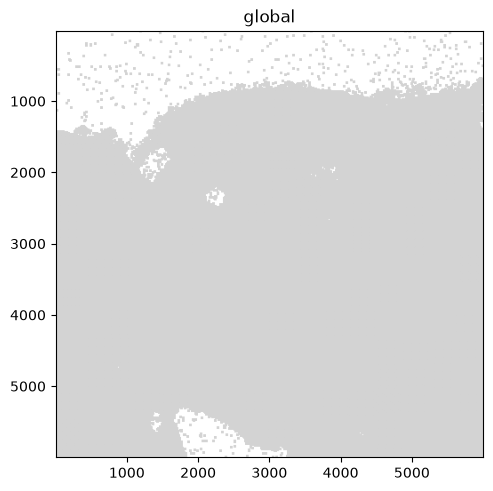

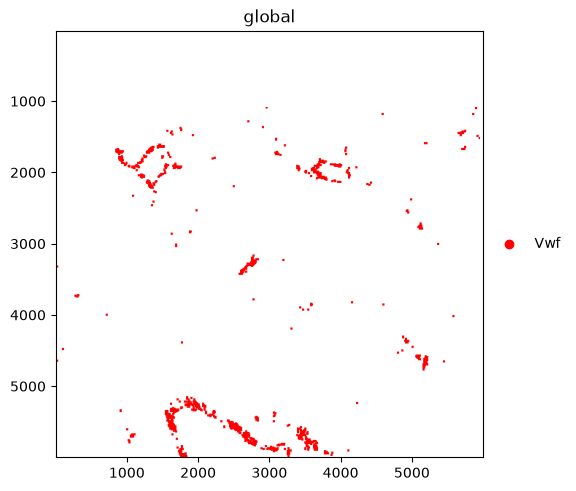

In [13]:
sdata.pl.render_points("transcripts").pl.show()
sdata.pl.render_points(
    "transcripts", color="gene", groups="Vwf", palette="red"
).pl.show()

### Shapes

Shapes are represented as `geopandas.GeoDataFrame` objects containing geometric objects like polygons.
For a comprehensive guide on working with `geopandas.GeoDataFrame` objects, please refer to the [`geopandas` documentation](https://geopandas.org/en/stable/docs.html).

In [14]:
sdata["nucleus_boundaries"]

,geometry
cell_ID,
99,"POLYGON ((6277 798, 6277 799, 6272 799, 6272 8..."
142,"POLYGON ((6427 6123, 6423 6123, 6423 6124, 641..."
208,"POLYGON ((3747 858, 3747 859, 3746 859, 3746 8..."
235,"POLYGON ((752 6144, 752 6145, 763 6145, 763 61..."
336,"POLYGON ((5174 935, 5174 936, 5172 936, 5172 9..."
...,...
7652,"POLYGON ((1094 6028, 1094 6029, 1091 6029, 109..."
7680,"POLYGON ((1324 6063, 1324 6064, 1320 6064, 132..."
7694,"POLYGON ((1692 6063, 1692 6064, 1686 6064, 168..."


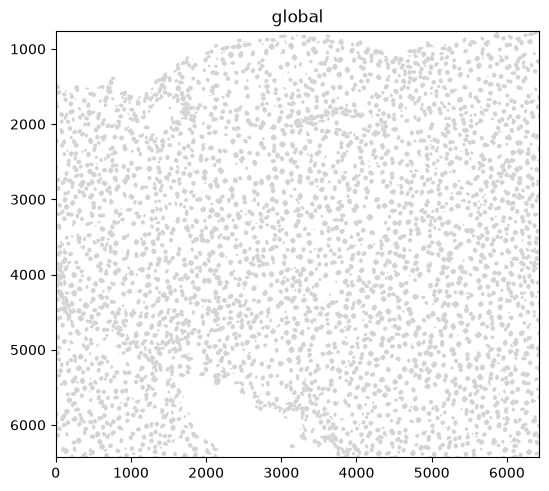

In [15]:
sdata.pl.render_shapes("nucleus_boundaries").pl.show()

### Tables

Annotated matrices are represented as `anndata.AnnData` objects.
Ingested datasets will usually have a table located at `sdata['table']` for a count/abundance matrix.
This enables downstream analysis with tools like Scanpy, scVI, etc.

For different spatial technologies this quantifies:
- transcriptomics: transcript counts;
- spatial proteomics: marker abundances;
- slide-based assays: spot/grid abundances ([see spatial chapter](../spatial/introduction.ipynb)).

In [16]:
sdata["table"]

AnnData object with n_obs × n_vars = 3375 × 99
    obs: 'cell_ID', 'fov_labels', 'annotation'
    uns: 'annotation_colors', 'spatialdata_attrs'
    obsm: 'spatial'
    layers: None (.X)

Here is an example of plotting numerical information on the cells (_HAL_ gene expression) and of plotting categorical information (cell types).

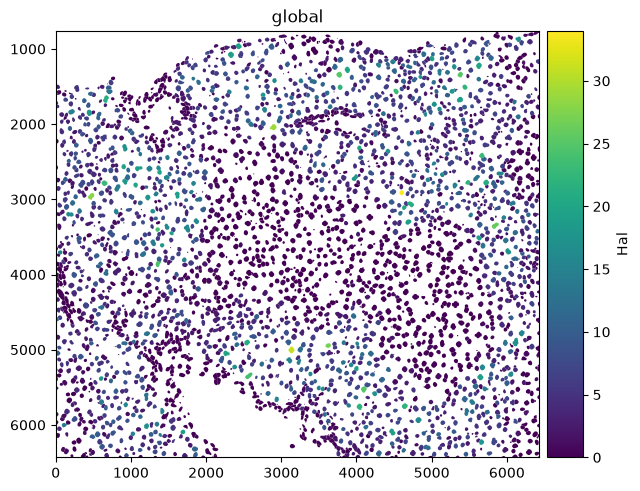

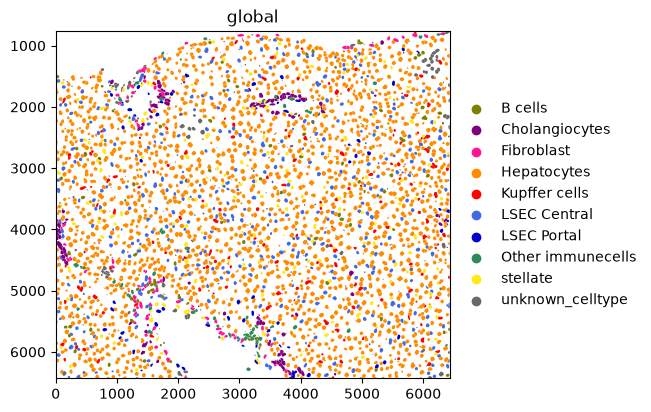

In [17]:
sdata.pl.render_shapes("nucleus_boundaries", color="Hal").pl.show()
sdata.pl.render_shapes("nucleus_boundaries", color="annotation").pl.show()

(spatial-data-structures-key-takeaway-2)=
## Spatial omics data analysis with Squidpy

Squidpy is a framework to analyze and visualize spatial omics data.
It was published around two years before SpatialData {cite:p}`at:Marconato2025,at:Palla2022`.
This is also why Squidpy was originally built on top of Scanpy and AnnData.
As the scverse ecosystem will gradually transition Squidpy to use SpatialData internally, this only gives a short introduction on how Squidpy uses spatial data.
Check out future changes and tutorials on the documentation of [SpatialData](https://spatialdata.scverse.org/en/stable/index.html) and [Squidpy](https://spatialdata.scverse.org/en/stable/index.html).

### API overview
Squidpy’s API lets you analyze and visualize spatial molecular data. 
Graph (`gr`) handles spatial relationships and interactions, image (`im`) processes and segments tissue images, tools (`tl`) provides spatial analysis, and plotting (`pl`) visualizes data and results. 
Reading (`read`) and datasets (`datasets`) support importing data and example datasets across technologies.

### Installation and importing packages
Squidpy is available on PyPI and Conda. 
It can be installed using either of the following commands.
```bash
pip install squidpy
conda install -c conda-forge squidpy
```

### SpatialData integration
Let`s start by importing Squidpy.

In [18]:
import scanpy as sc
import squidpy as sq

We can load a Xenium dataset with `lamindb`.

In [19]:
sdata = ln.Artifact.get(
    key="introduction/advanced_data_structures_and_frameworks_squidpy.zarr"
).load()
sdata

SpatialData object, with associated Zarr store: /home/lheumos/.cache/lamindb/lamin-eu-central-1/VPwcjx3CDAa2/introduction/advanced_data_structures_and_frameworks_squidpy.zarr
├── Images
│     ├── 'morphology_focus': DataTree[cyx] (1, 25778, 35416), (1, 12889, 17708), (1, 6444, 8854), (1, 3222, 4427), (1, 1611, 2213)
│     └── 'morphology_mip': DataTree[cyx] (1, 25778, 35416), (1, 12889, 17708), (1, 6444, 8854), (1, 3222, 4427), (1, 1611, 2213)
├── Points
│     └── 'transcripts': DataFrame with shape: (42638083, 8) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (167780, 1) (2D shapes)
│     └── 'cell_circles': GeoDataFrame shape: (167780, 2) (2D shapes)
└── Tables
      └── 'table': AnnData (167780, 313)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), morphology_mip (Images), transcripts (Points), cell_boundaries (Shapes), cell_circles (Shapes)

### Squidpy demo

Let's compute a nearest neighbor graph of the spatial coordinates of the xenium dataset.

In [20]:
sq.gr.spatial_neighbors(sdata["table"])

INFO     Creating graph using `generic` coordinates and `None` transform and `1` libraries.                        


After that, we can cluster the cells based on gene expression profiles and compute clustering.

In [21]:
%%time
sc.pp.pca(sdata["table"])
sc.pp.neighbors(sdata["table"])
sc.tl.leiden(sdata["table"], flavor="igraph", n_iterations=2)

CPU times: user 53.7 s, sys: 2.66 s, total: 56.3 s
Wall time: 42.7 s


And run the neighbor enrichment analysis in Squidpy.

100%|██████████| 1000/1000 [00:08<00:00, 115.47/s]


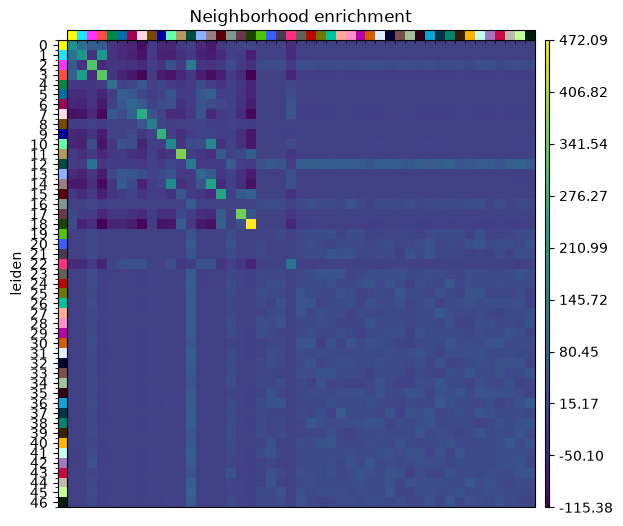

In [22]:
sq.gr.nhood_enrichment(sdata["table"], cluster_key="leiden")
sq.pl.nhood_enrichment(sdata["table"], cluster_key="leiden", figsize=(5, 5))

We can finally visualize the results in spatial coordinates both with Squidpy as well as with the novel plotting function in SpatialData.


CPU times: user 98.6 ms, sys: 4.98 ms, total: 104 ms
Wall time: 134 ms


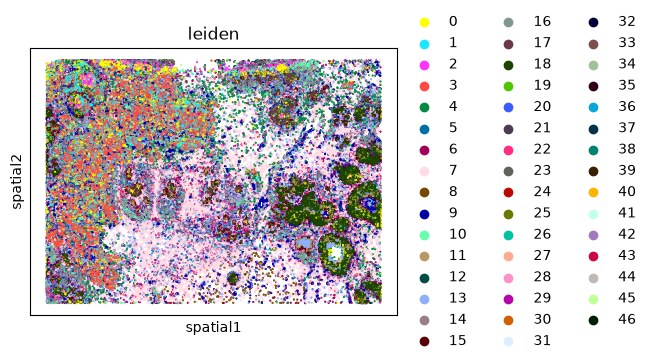

In [23]:
%%time
sq.pl.spatial_scatter(sdata["table"], shape=None, color="leiden")

## Questions
### Flipcards

In [24]:
%run ../../scripts/quiz.py

with quiz_tabs():
    flip_card(
        "q1",
        "What is the main purpose of Squidpy?",
        "Squidpy is a tool to analyze and visualize spatial omics data.",
    )

### Multiple-choice questions

In [25]:
%run ../../scripts/quiz.py

with quiz_tabs():
    multiple_choice_question(
        question_id="q2",
        question="In a SpatialData object, where are the X/Y coordinates of a table (AnnData object) stored?",
        options=[
            ".var",
            ".obs",
            ".obsm['spatial']",
            ".layers['spatial']",
        ],
        correct_answer=".obsm['spatial']",
        explanations={
            ".var": "`.var` contains gene-level metadata, not spatial coordinates.",
            ".obs": "`.obs` contains cell-level metadata but not coordinate arrays.",
            ".layers['spatial']": "`.layers` can store alternate matrices, but spatial coordinates are in `.obsm`.",
        },
    )

    multiple_choice_question(
        question_id="q3",
        question="SpatialData differs from AnnData because it:",
        options=[
            "Replaces gene expression matrices",
            "Stores only image data",
            "Integrates spatial elements like images and geometries",
            "Works only with multimodal sequencing",
        ],
        correct_answer="Integrates spatial elements like images and geometries",
        explanations={
            "Replaces gene expression matrices": "SpatialData still supports expression matrices. It does not replace them.",
            "Stores only image data": "SpatialData can store images, but also tables and coordinates.",
            "Works only with multimodal sequencing": "SpatialData is not restricted to multimodal sequencing. It adds spatial context.",
        },
    )

## Contributors

We gratefully acknowledge the contributions of:

### Authors

* Lukas Heumos
* Luis Heinzlmeier

### Reviewers

* Isaac Virshup